In [ ]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import random

# global variables
SIZE = 32
STEPS = 100
EVAL_REP = 3
MUTATION_PROBABILITY = 0.005

In [ ]:
def calc_neighborhood(matrix):
    # from ____ side:
    left = np.roll(matrix, 1, 1) 
    right = np.roll(matrix, -1, 1)

    top = np.roll(matrix, 1, 0)
    top_left = np.roll(top, 1, 1)
    top_right = np.roll(top, -1, 1)

    bottom = np.roll(matrix, -1, 0)
    bottom_left = np.roll(bottom, 1, 1) 
    bottom_right = np.roll(bottom, -1, 1)

    a = [
        top_left, top, top_right,
        left, matrix, right,
        bottom_left, bottom, bottom_right
        ]
    
    powers = 2 ** np.arange(9)

    return sum(neighbor * power for neighbor, power in zip(a, powers))

def gen_matrix(size):
    return np.random.randint(0, 2, size=(size, size))

def gen_chromosome():
    return np.random.randint(0,2, 512)

def apply_ruleset(neighboorhood, chromosome):
    return (chromosome[neighboorhood]).astype(np.int32)

def calc_score(matrix):
    # Get forward-looking neighbors to match instructions and avoid double-counting
    right = np.roll(matrix, -1, 1)        # (x+1, y)
    bottom = np.roll(matrix, -1, 0)       # (x, y+1)
    
    bottom_right = np.roll(bottom, -1, 1) # (x+1, y+1)
    
    top = np.roll(matrix, 1, 0)
    top_right = np.roll(top, -1, 1)       # (x+1, y-1)

    # "Subtract 3 points if cell (x+1,y) or (x,y+1) is in the same state as (x,y)"
    # Using bitwise OR (|) for the condition
    cond1 = (matrix == right) | (matrix == bottom)

    # "Otherwise..." 
    # add 8 points if cell (x+1, y + 1) is same, subtract 5 if not
    diag1_score = np.where(matrix == bottom_right, 8, -5)
    # likewise add 8 points if cell (x+1,y-1) is same, subtract 5 if not
    diag2_score = np.where(matrix == top_right, 8, -5)

    # Apply the if/else logic across the entire grid
    scores = np.where(cond1, -3, diag1_score + diag2_score)

    return np.sum(scores)

def evaluate_chromosome(chromosome):
    scores = []
    for _ in range(EVAL_REP):
        matrix = gen_matrix(SIZE)
        step_scores = []
        
        for step in range(STEPS):
            neigh = calc_neighborhood(matrix)
            matrix = apply_ruleset(neigh, chromosome)
            
            # Average the value over the last 5 timesteps
            if step >= STEPS - 5:
                step_scores.append(calc_score(matrix))
                
        scores.append(np.average(step_scores))

    return np.average(scores)

def clone_perfect(chromosome):
    return chromosome.copy()

def clone_mutate(chromosome):
    return mutate(chromosome.copy())

def mutate(chromosome):
    mask = np.random.random(chromosome.shape) < MUTATION_PROBABILITY
    return chromosome ^ mask.astype(np.int8)
    
def procreate(parent1, parent2):
    mask = np.random.random(parent1.shape) < 0.5
    child = np.where(mask, parent1, parent2)
    return mutate(child)

def run_evolution(generations, population, survival_rate):
    """
    This function runs the genetic algoritm, after each generation
    the survivors randomly procrete with each other.
    """

    history = []

    # initial population
    pop = [gen_chromosome() for _ in range(population)]

    best_chromosome = None
    best_score = -np.inf

    for gen in range(generations):
        # evaluate the population
        scores = np.array([evaluate_chromosome(c) for c in pop])

        # track the best score
        idx_best = np.argmax(scores)
        if scores[idx_best] > best_score:
            best_score = scores[idx_best]
            best_chromosome = pop[idx_best].copy()

        history.append(best_score)

        # select survivors
        num_survivors = max(2, int(population * survival_rate))
        survivor_idx = np.argsort(scores)[-num_survivors:]
        survivors = [pop[i] for i in survivor_idx]

        # reproduction
        new_pop = []

        # keep best survivor
        new_pop.append(clone(pop[idx_best]))

        # breeding
        while len(new_pop) < population:
            p1, p2 = random.choice(survivors), random.choice(survivors)
            child = procreate(p1,p2)
            new_pop.append(child)
        
        pop = new_pop

        print(f"Gen {gen}: best={best_score:03d}")
    
    return best_chromosome, history

def animate(chromosome, filename):
    matrix = gen_matrix(SIZE*2)
    frames = []

    for i in range(STEPS*3):
        neigh = calc_neighborhood(matrix)
        matrix = apply_ruleset(neigh, chromosome)

        fig, ax = plt.subplots()
        ax.matshow(matrix, cmap="viridis")
        ax.axis("off")

        fig.canvas.draw()

        frame = np.asarray(fig.canvas.buffer_rgba()) 
        frames.append(frame)

        plt.close(fig)

    imageio.mimsave(f"{filename}.gif", frames, fps=24, loop=0)

Gen 0: best=-1336.4
Gen 1: best=-1200.8666666666666
Gen 2: best=-1166.4666666666667
Gen 3: best=-1166.4666666666667
Gen 4: best=-1155.8
Gen 5: best=-976.2666666666668
Gen 6: best=-924.5333333333334
Gen 7: best=-924.5333333333334
Gen 8: best=-863.8666666666667
Gen 9: best=-766.1999999999999
Gen 10: best=-658.0666666666667
Gen 11: best=-658.0666666666667
Gen 12: best=-658.0666666666667
Gen 13: best=-553.6
Gen 14: best=-519.4666666666667
Gen 15: best=-519.4666666666667
Gen 16: best=-235.86666666666667
Gen 17: best=-216.33333333333334
Gen 18: best=99.60000000000002
Gen 19: best=99.60000000000002
Gen 20: best=369.93333333333334
Gen 21: best=369.93333333333334
Gen 22: best=748.7333333333332
Gen 23: best=1817.1999999999998
Gen 24: best=1817.1999999999998
Gen 25: best=4615.266666666667
Gen 26: best=4615.266666666667
Gen 27: best=4615.266666666667
Gen 28: best=4655.933333333333
Gen 29: best=7691.933333333334
Gen 30: best=7691.933333333334
Gen 31: best=10006.066666666666
Gen 32: best=10960.06666

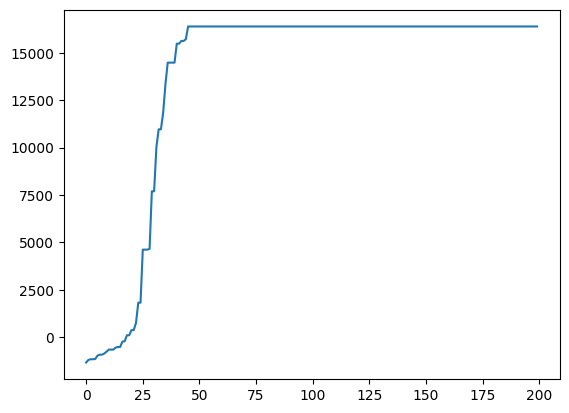

In [116]:
best_chromosome, history = run_evolution(200, 16, 0.5)
plt.plot(history)

In [129]:
animate(best_chromosome, "test")